# B2 — Pembentukan Citra dan Ruang Warna (SIMUTEH)
Nama: Prima Pratama Putra · NIM 2330511022 · **SEED = 1022**

## Langkah 2.1 Lembar hitung manual (verifikasi dengan kode)
Data Tabel 7: f = 4,0 mm; piksel sensor 0,0014 mm; foto asli 4000 x 3000, 3 kanal, 8 bit; X = 5 mm; Z = 300 mm; bercak (R,G,B)=(196,178,86); daun sehat (52,136,60).

In [13]:
import sys
sys.path.append("../src")
import cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil, kontras_bercak

f, piksel, X, Z = 4.0, 0.0014, 5.0, 300.0  # mm
# a) x = f X / Z
x = f * X / Z
print(f"a) x = {f} * {X} / {Z} = {x:.4f} mm -> {x/piksel:.2f} piksel")
# b) Z = 600
x2 = f * X / 600
print(f"b) Z=600: x = {x2:.4f} mm -> {x2/piksel:.2f} piksel (jarak 2x, ukuran 1/2x)")
# c) minimal 10 piksel: x >= 10 * 0.0014 mm -> Z <= f X / x
Zmaks = f * X / (10 * piksel)
print(f"c) Z maks (>=10 px, foto asli) = {f}*{X}/(10*{piksel}) = {Zmaks:.1f} mm = {Zmaks/10:.1f} cm")
# d) diperkecil 4000 -> 640 (faktor 0.16)
fak = 640 / 4000
d_kecil = x / piksel * fak
Zmaks_kecil = f * X / ((10 / fak) * piksel)
print(f"d) faktor {fak}: diameter = {x/piksel:.2f} * {fak} = {d_kecil:.2f} px; "
      f"Z maks agar >=10 px = {Zmaks_kecil:.1f} mm = {Zmaks_kecil/10:.1f} cm")
# e) memori
m_asli = 4000 * 3000 * 3 * 8 // 8
m_640c = 640 * 480 * 3
m_640g = 640 * 480 * 1
print(f"e) asli = {m_asli:,} B ({m_asli/1e6:.1f} MB, {m_asli/2**20:.2f} MiB); 640x480 warna = {m_640c:,} B ({m_640c/1024:.0f} KiB); "
      f"640x480 keabuan = {m_640g:,} B ({m_640g/1024:.0f} KiB)")
tot = 300 * m_asli
print(f"   300 foto asli = {tot:,} B = {tot/1e9:.2f} GB = {tot/2**30:.2f} GiB")
# f) aras keabuan dan Hue
bercak, daun = (196, 178, 86), (52, 136, 60)
yb = 0.299 * bercak[0] + 0.587 * bercak[1] + 0.114 * bercak[2]
yd = 0.299 * daun[0] + 0.587 * daun[1] + 0.114 * daun[2]
print(f"f) Y bercak = {yb:.3f} (~{round(yb)}), Y daun = {yd:.3f} (~{round(yd)}), selisih = {round(yb)-round(yd)}")
for nama, rgb in [("bercak", bercak), ("daun", daun)]:
    bgr = np.uint8([[rgb[::-1]]])
    print(f"   cv2 {nama}: gray = {cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)[0,0]}, HSV = {cv2.cvtColor(bgr, cv2.COLOR_BGR2HSV)[0,0]}")

a) x = 4.0 * 5.0 / 300.0 = 0.0667 mm -> 47.62 piksel
b) Z=600: x = 0.0333 mm -> 23.81 piksel (jarak 2x, ukuran 1/2x)
c) Z maks (>=10 px, foto asli) = 4.0*5.0/(10*0.0014) = 1428.6 mm = 142.9 cm
d) faktor 0.16: diameter = 47.62 * 0.16 = 7.62 px; Z maks agar >=10 px = 228.6 mm = 22.9 cm
e) asli = 36,000,000 B (36.0 MB, 34.33 MiB); 640x480 warna = 921,600 B (900 KiB); 640x480 keabuan = 307,200 B (300 KiB)
   300 foto asli = 10,800,000,000 B = 10.80 GB = 10.06 GiB
f) Y bercak = 172.894 (~173), Y daun = 102.220 (~102), selisih = 71
   cv2 bercak: gray = 173, HSV = [ 25 143 196]
   cv2 daun: gray = 102, HSV = [ 63 158 136]


## Langkah 2.2 Rencana akuisisi citra
| Variabel | Ketentuan |
|---|---|
| Jarak dan sudut | Kamera tegak lurus di atas daun pada jarak 20 cm (batas maksimum 22,9 cm agar bercak 5 mm tetap ≥ 10 px setelah diperkecil ke lebar 640 px, lihat 2.1 d), memakai penyangga |
| Resolusi minimum | 4000 x 3000 piksel, disimpan penuh, baru diperkecil ke lebar 640 px saat praproses |
| Alas dan acuan ukuran | Nampan atau kertas polos matte, penggaris di tepi bingkai |
| Kondisi cahaya | Lima kondisi: normal, gelap, terang, kontras rendah, bayangan; tanpa lampu kilat |
| Jumlah citra | Minimal 20 per kelas (sehat, ringan, berat), merata di lima kondisi |
| Penamaan berkas | `teh_[kelas]_[kondisi]_[nomor].jpg`, contoh `teh_berat_gelap_007.jpg` |
| Perangkat | Satu jenis ponsel, JPEG, tanpa zoom digital, HDR, filter, atau mode kecantikan |
| Izin | Izin tertulis ketua kelompok tani, memuat tujuan, penyimpanan, dan hak menarik izin |
| Metadata dan wajah | GPS dimatikan, EXIF dibersihkan, foto yang memuat orang dihapus |

## Langkah 2.3 Kanal warna (Kode 2.1)

KB kanal B   : 2.50
KB kanal G   : 1.23
KB kanal R   : 9.03
KB kanal Gray: 4.60
KB kanal H   : 6.67
KB kanal S   : 1.05
KB kanal V   : 3.19


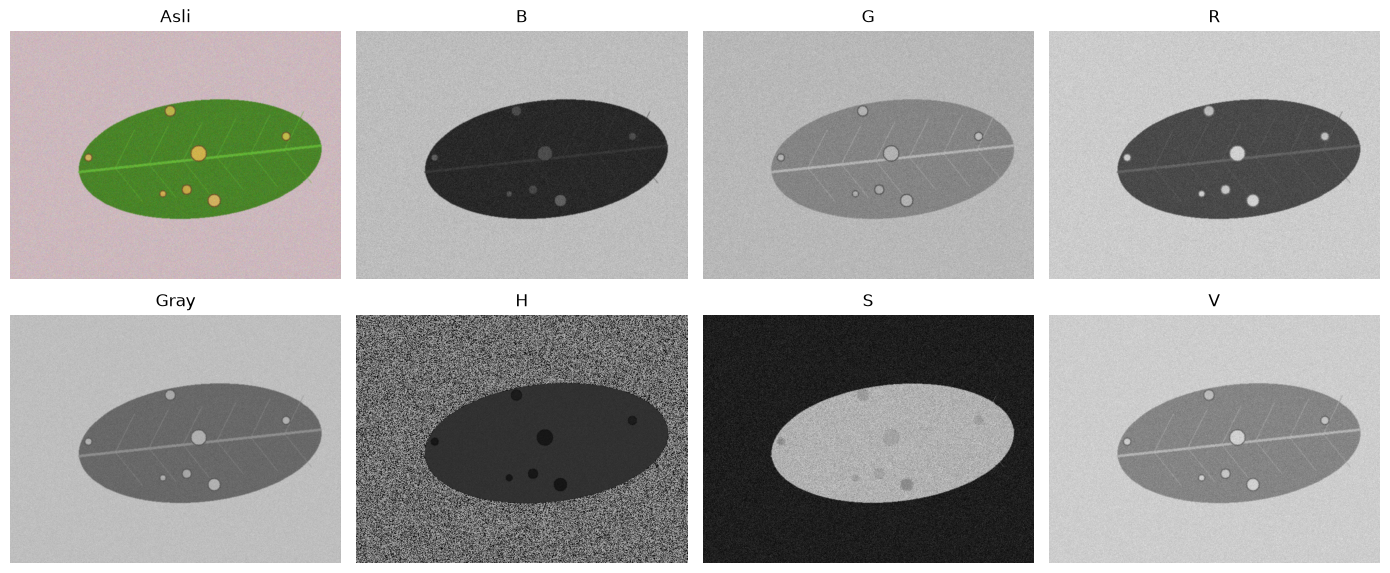

In [14]:
nama = "teh_041.png" # kelas berat, kondisi normal
img = baca(f"../data/sintetis/citra/{nama}")
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
b, g, r = cv2.split(img)
h, s, v = cv2.split(hsv)
kanal = {"B": b, "G": g, "R": r, "Gray": gray, "H": h, "S": s, "V": v}
tampil([img] + list(kanal.values()), ["Asli"] + list(kanal.keys()),
       baris=2, ukuran=(14, 6))
plt.savefig("../hasil/b2_panel_kanal.png", dpi=120)
for nm, c in kanal.items():
    print(f"KB kanal {nm:4s}: {kontras_bercak(c, md, mb):.2f}")

## Langkah 2.4 Sampling dan kuantisasi (Kode 2.2)

fx=0.5: ukuran (240, 320), KB=5.46
fx=0.2: ukuran (96, 128), KB=4.87
fx=0.1: ukuran (48, 64), KB=3.37
fx=0.05: ukuran (24, 32), KB=1.57


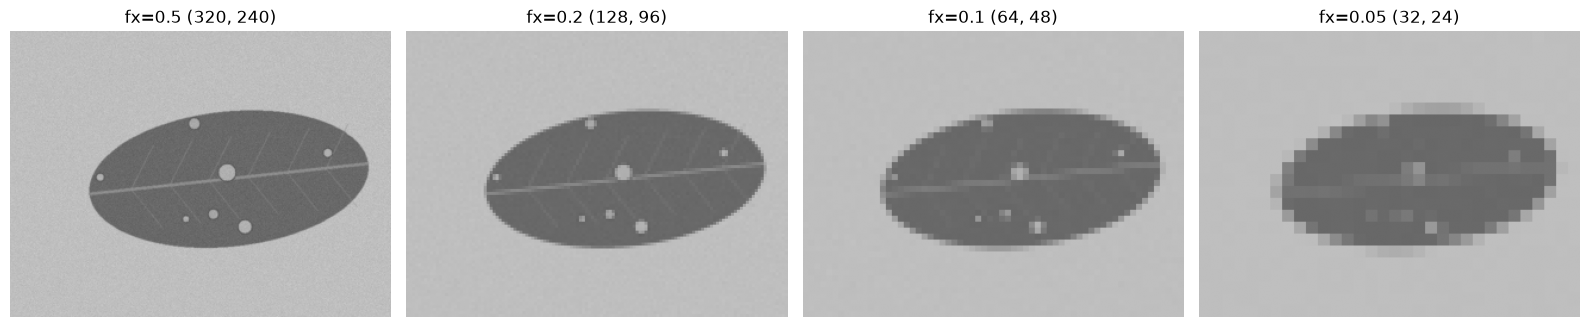

k=1: 2 level, KB=3.68
k=2: 3 level, KB=3.69
k=3: 5 level, KB=3.59
k=4: 10 level, KB=4.26
k=8: 144 level, KB=4.60


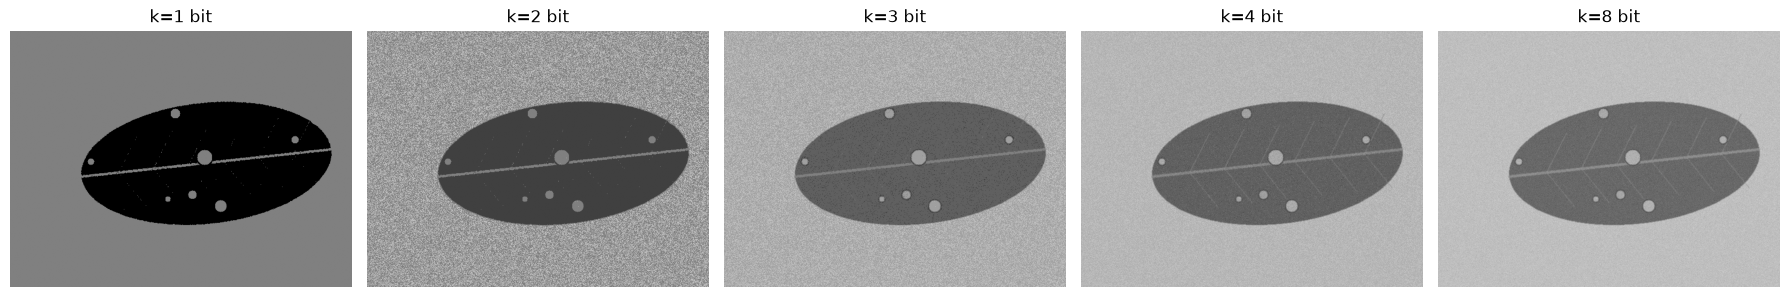

In [15]:
# sampling: perkecil lalu perbesar kembali ke ukuran semula
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a, fx in zip(ax, [0.5, 0.2, 0.1, 0.05]):
    kecil = cv2.resize(gray, None, fx=fx, fy=fx, interpolation=cv2.INTER_AREA)
    besar = cv2.resize(kecil, gray.shape[::-1],
                       interpolation=cv2.INTER_NEAREST)
    print(f"fx={fx}: ukuran {kecil.shape}, KB={kontras_bercak(besar, md, mb):.2f}")
    a.imshow(besar, cmap="gray", vmin=0, vmax=255); a.set_title(f"fx={fx} {kecil.shape[::-1]}"); a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b2_sampling.png", dpi=120); plt.show()
# kuantisasi: sisakan k bit
fig, ax = plt.subplots(1, 5, figsize=(18, 3.2))
for a, k in zip(ax, [1, 2, 3, 4, 8]):
    langkah = 256 // (2 ** k)
    kuant = (gray // langkah) * langkah
    print(f"k={k}: {len(np.unique(kuant))} level, "
          f"KB={kontras_bercak(kuant, md, mb):.2f}")
    a.imshow(kuant, cmap="gray", vmin=0, vmax=255); a.set_title(f"k={k} bit"); a.axis("off")
plt.tight_layout(); plt.savefig("../hasil/b2_kuantisasi.png", dpi=120); plt.show()

## Langkah 2.5 KB seluruh kondisi cahaya, kelas berat (Kode 2.3, Tabel 8)

In [16]:
def semua_kanal(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    b, g, r = cv2.split(img); h, s, v = cv2.split(hsv)
    return {"B": b, "G": g, "R": r,
            "Gray": cv2.cvtColor(img, cv2.COLOR_BGR2GRAY),
            "H": h, "S": s, "V": v}

label = pd.read_csv("../data/sintetis/label.csv")

def tabel_kelas(kelas):
    baris = []
    for _, d in label[label.kelas == kelas].iterrows():
        im = baca(f"../data/sintetis/citra/{d.nama_file}")
        m_d = cv2.imread(f"../data/sintetis/mask_daun/{d.nama_file}", 0)
        m_b = cv2.imread(f"../data/sintetis/mask_bercak/{d.nama_file}", 0)
        kb = {k: kontras_bercak(c, m_d, m_b) for k, c in semua_kanal(im).items()}
        kb["kondisi"] = d.kondisi_cahaya
        baris.append(kb)
    return pd.DataFrame(baris).groupby("kondisi").mean().round(2)

urut = ["normal", "gelap", "terang", "kontras_rendah", "bayangan"]
tabel_kb = tabel_kelas("berat").loc[urut]
print(tabel_kb)
tabel_kb.to_csv("../hasil/b2_kb_kanal.csv")

                   B     G      R  Gray     H     S     V
kondisi                                                  
normal          2.58  0.92   8.87  4.46  6.59  1.49  2.68
gelap           1.50  1.91  10.98  5.31  5.64  0.98  3.77
terang          2.00  0.45   7.44  3.82  6.33  1.42  1.63
kontras_rendah  0.92  0.82   4.26  2.69  2.00  0.06  1.85
bayangan        1.33  0.40   4.74  1.61  4.49  0.84  1.01


## Langkah 2.6 Kelas ringan dan kanal terbaik

In [17]:
tabel_kb_ringan = tabel_kelas("ringan").loc[urut]
print("KB kelas ringan:"); print(tabel_kb_ringan)
tabel_kb_ringan.to_csv("../hasil/b2_kb_kanal_ringan.csv")
print("\nRerata KB seluruh kondisi (berat):"); print(tabel_kb.mean().round(2).sort_values(ascending=False))
print("\nRerata KB seluruh kondisi (ringan):"); print(tabel_kb_ringan.mean().round(2).sort_values(ascending=False))

KB kelas ringan:
                   B     G     R  Gray     H     S     V
kondisi                                                 
normal          1.72  0.77  8.39  3.92  6.41  0.81  2.34
gelap           0.93  0.70  8.80  2.29  7.13  1.17  1.34
terang          1.40  0.55  5.60  2.15  5.13  1.39  0.45
kontras_rendah  0.74  0.34  3.59  1.49  2.15  0.50  0.73
bayangan        1.02  0.49  5.46  1.62  5.24  0.66  0.96

Rerata KB seluruh kondisi (berat):
R       7.26
H       5.01
Gray    3.58
V       2.19
B       1.67
S       0.96
G       0.90
dtype: float64

Rerata KB seluruh kondisi (ringan):
R       6.37
H       5.21
Gray    2.29
V       1.16
B       1.16
S       0.91
G       0.57
dtype: float64


Kanal terbaik (rerata KB kelas berat): R
teh_021.png -> kanal terbaik: R {'B': np.float64(2.53), 'G': np.float64(0.05), 'R': np.float64(8.41), 'Gray': np.float64(3.43), 'H': np.float64(7.14), 'S': np.float64(2.08), 'V': np.float64(1.42)}
teh_045.png -> kanal terbaik: H {'B': np.float64(2.35), 'G': np.float64(0.0), 'R': np.float64(4.63), 'Gray': np.float64(1.23), 'H': np.float64(6.42), 'S': np.float64(2.1), 'V': np.float64(0.55)}


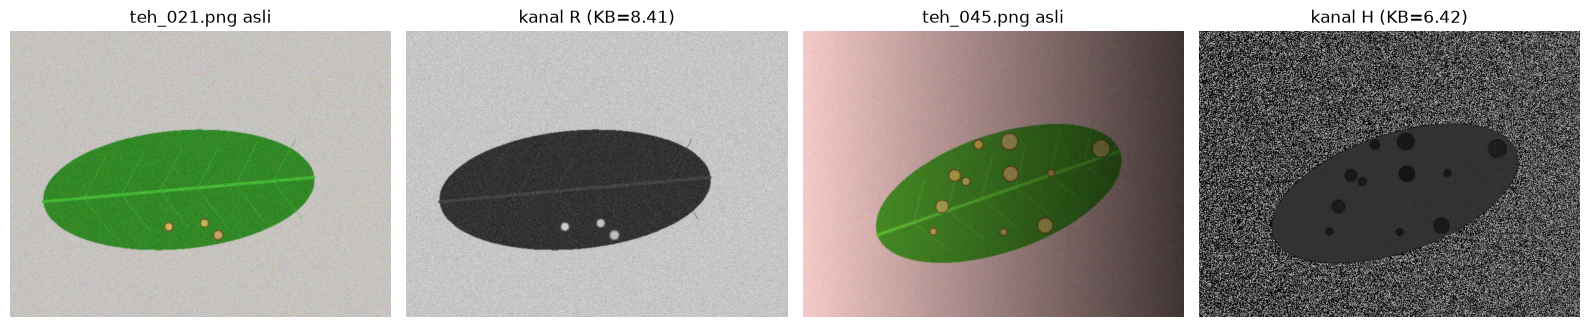

In [18]:
# kanal terbaik untuk teh_021 (ringan, normal) dan teh_045 (berat, bayangan)
KANAL_TERBAIK = tabel_kb.mean().idxmax()
print("Kanal terbaik (rerata KB kelas berat):", KANAL_TERBAIK)
fig_list, fig_jd = [], []
for nm in ["teh_021.png", "teh_045.png"]:
    im = baca(f"../data/sintetis/citra/{nm}")
    m_d = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    m_b = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    kn = semua_kanal(im)
    kb = {k: kontras_bercak(c, m_d, m_b) for k, c in kn.items()}
    best = max(kb, key=kb.get)
    print(nm, "-> kanal terbaik:", best, {k: round(v, 2) for k, v in kb.items()})
    fig_list += [im, kn[best]]; fig_jd += [f"{nm} asli", f"kanal {best} (KB={kb[best]:.2f})"]
tampil(fig_list, fig_jd, baris=1, ukuran=(16, 3.6))
plt.savefig("../hasil/b2_kanal_terbaik.png", dpi=120)